# Crash!💥 Boom!💥 Bang! 💥🚗🚙💥🚗
**A SQL based exploratory data analysis of traffic accidents in Okinawa, Japan**

---   
# <span style="color:#0279f0;">Part 5: Categorical Analysis</span>
---

We know where and when accidents happened. Now let's look at what kind of accidents they were, who was involved, and what the conditions were like.

**Analysis Tasks**
1. **Accident Types** – Compare the most common types and how often they were fatal.
2. **Age Groups** – Check which age groups appear most often for Party A and Party B.
3. **Weather & Road Surface** – See what conditions were recorded at the time of the crash.

**Tools used in this notebook**
- Pandas – for loading the CSV.
- DuckDB – for decoding categories and aggregating counts.
- Matplotlib / Seaborn – for visualisations.

📖 **Code reference** [National Police Agency 2024 codebook (PDF)](https://www.npa.go.jp/publications/statistics/koutsuu/opendata/2024/codebook_2024.pdf)

##### 👩🏻‍💻 *<span style="color:#0279f0">Loading data to begin...</span>*

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

for folder in (project_root, project_root / "notebooks"):
    if str(folder) not in sys.path:
        sys.path.append(str(folder))

from sql.notebook_setup import create_connection, load_data, print_summary, register_table

# Load data with pandas
accidents_df = load_data(project_root / "data" / "okinawa_2024_accidents.csv")

# Connect to DuckDB and register the accidents table
conn = create_connection()
register_table(conn, "accidents", accidents_df)
print_summary(accidents_df, "Accidents Table", max_cols=10)


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


✅ Accidents Table: 2,749 records
----------------------------------------
✅ Showing 10 of 68 columns:
 1. data_category
 2. prefecture_code
 3. police_station_code
 4. report_id
 5. accident_details_code
 6. fatalities
 7. injured_persons
 8. route_code
 9. location_code
10. municipality_code
... 58 additional columns


---
### **5.1 Accident Types**
Which types made up most of the accidents? Which types accounted for the most fatal crashes?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Accident Types...</span>*

,accident_type_code,accident_type,accident_count,fatal_crashes,fatalities,pct_of_all_accidents,fatal_crash_pct
0,21,Vehicle–vehicle,2217,11,11.0,80.65,0.50
1,1,Pedestrian–vehicle,469,17,18.0,17.06,3.62
2,41,Single vehicle,63,15,15.0,2.29,23.81


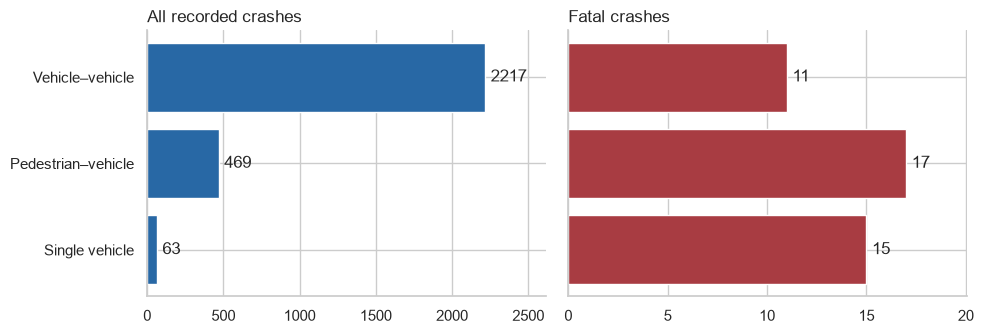

In [2]:
# ========================================
# Accident counts and severity by type
# ========================================
query_types = """
SELECT
    accident_type_code,
    CASE accident_type_code
        WHEN 1 THEN 'Pedestrian–vehicle'
        WHEN 21 THEN 'Vehicle–vehicle'
        WHEN 41 THEN 'Single vehicle'
        WHEN 61 THEN 'Train'
        ELSE 'Unmapped code'
    END AS accident_type,
    COUNT(*) AS accident_count,
    COUNT(*) FILTER (WHERE accident_details_code = 1) AS fatal_crashes,
    SUM(fatalities) AS fatalities,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_of_all_accidents,
    ROUND(COUNT(*) FILTER (WHERE accident_details_code = 1) * 100.0 / COUNT(*), 2)
        AS fatal_crash_pct
FROM accidents
GROUP BY ALL
ORDER BY accident_count DESC
"""
results_types = conn.execute(query_types).fetchdf()
display(results_types)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
ax1.barh(results_types["accident_type"], results_types["accident_count"], color="#2868a5")
ax2.barh(results_types["accident_type"], results_types["fatal_crashes"], color="#a83c42")
ax1.invert_yaxis()
ax1.set_title("All recorded crashes", loc="left")
ax2.set_title("Fatal crashes", loc="left")
for ax in (ax1, ax2):
    ax.bar_label(ax.containers[0], fmt="%g", padding=4)
    ax.margins(x=0.18)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 <span style="color:orange;">5.1 Key Findings</span>

- **Vehicle–vehicle** crashes were the most common, with **2,217 crashes (80.65%)**.
- **Pedestrian–vehicle** crashes accounted for **17 of the 43 fatal crashes**, the most of any type.
- **Single-vehicle** crashes accounted for only **63 crashes**, but **15 were fatal (23.81%)**. The group is small, so a few crashes can shift that percentage.
- The fatal share tells us how often a *recorded crash* in that group was fatal. To measure risk on the road, we would need counts of trips or another measure of exposure.

---
### **5.2 Age Groups**
Which age bands appear most often in each of the two recorded party fields?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Age Groups...</span>*

,party,age_code,age_group,party_records,pct_of_party_records
0,Party A,1,0–24,462,16.81
1,Party B,1,0–24,615,22.37
2,Party A,25,25–34,493,17.93
3,Party B,25,25–34,430,15.64
4,Party A,35,35–44,437,15.90
5,Party B,35,35–44,461,16.77
6,Party A,45,45–54,413,15.02
7,Party B,45,45–54,451,16.41
8,Party A,55,55–64,354,12.88
9,Party B,55,55–64,301,10.95


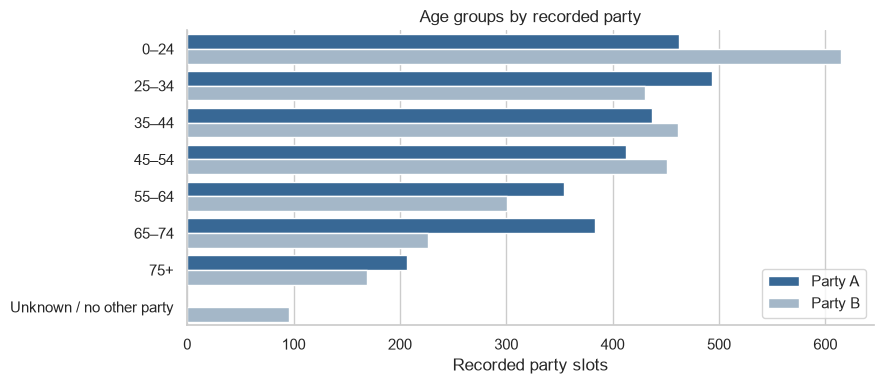

In [3]:
# ========================================
# Stack the two recorded party slots
# ========================================
query_age = """
WITH parties AS (
    SELECT 'Party A' AS party, age_party_a AS age_code
    FROM accidents
    UNION ALL
    SELECT 'Party B' AS party, age_party_b AS age_code
    FROM accidents
)
SELECT
    party,
    age_code,
    CASE age_code
        WHEN 0 THEN 'Unknown / no other party'
        WHEN 1 THEN '0–24'
        WHEN 25 THEN '25–34'
        WHEN 35 THEN '35–44'
        WHEN 45 THEN '45–54'
        WHEN 55 THEN '55–64'
        WHEN 65 THEN '65–74'
        WHEN 75 THEN '75+'
        ELSE 'Unmapped code'
    END AS age_group,
    COUNT(*) AS party_records,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY party), 2)
        AS pct_of_party_records
FROM parties
GROUP BY party, age_code
ORDER BY CASE WHEN age_code = 0 THEN 99 ELSE age_code END, party
"""
results_age = conn.execute(query_age).fetchdf()
display(results_age)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=results_age, y="age_group", x="party_records", hue="party",
    palette=["#2868a5", "#9eb7ce"], ax=ax
)
ax.set(xlabel="Recorded party slots", ylabel="", title="Age groups by recorded party")
ax.legend(title=None)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 <span style="color:orange;">5.2 Key Findings</span>

- **25–34** was the most common age band for **Party A** (493 records). **0–24** was the most common for **Party B** (615 records).
- **96 Party B slots** had code 0. The NPA uses this code for an unidentified party or the other-party slot in a single-vehicle crash.
- The chart counts entries in the two party fields. A crash can contribute to both bars, and the entries can include pedestrians and other road users. The age bands also cover different numbers of years.

---
### **5.3 Weather & Road Surface**
What were the conditions at the time of the crash?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Weather & Road Surface...</span>*

,category,condition,accident_count,fatal_crashes,pct_of_all_accidents
0,Weather,Clear,1643,27,59.77
1,Weather,Cloudy,659,12,23.97
2,Weather,Rain,447,4,16.26
3,Road surface,Dry pavement,2183,37,79.41
4,Road surface,Wet pavement,564,6,20.52
5,Road surface,Unpaved,2,0,0.07


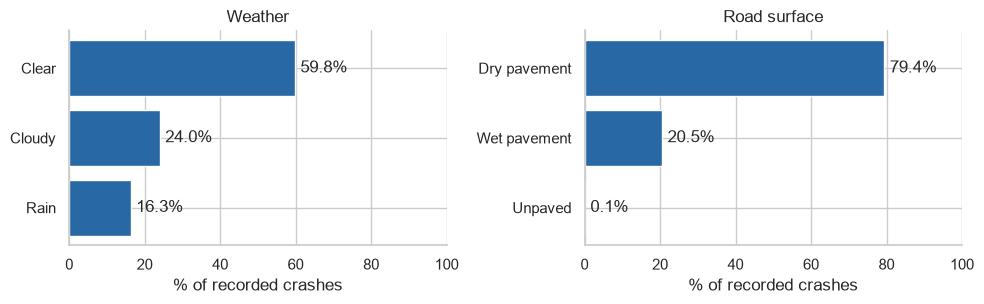

In [4]:
# ========================================
# Keep weather and surface denominators separate
# ========================================
query_conditions = """
WITH conditions AS (
    SELECT
        'Weather' AS category,
        CASE weather_code
            WHEN 1 THEN 'Clear'
            WHEN 2 THEN 'Cloudy'
            WHEN 3 THEN 'Rain'
            WHEN 4 THEN 'Fog'
            WHEN 5 THEN 'Snow'
            ELSE 'Unmapped code'
        END AS condition,
        accident_details_code
    FROM accidents
    UNION ALL
    SELECT
        'Road surface' AS category,
        CASE road_condition_code
            WHEN 1 THEN 'Dry pavement'
            WHEN 2 THEN 'Wet pavement'
            WHEN 3 THEN 'Icy pavement'
            WHEN 4 THEN 'Snow-covered pavement'
            WHEN 5 THEN 'Unpaved'
            ELSE 'Unmapped code'
        END AS condition,
        accident_details_code
    FROM accidents
)
SELECT
    category,
    condition,
    COUNT(*) AS accident_count,
    COUNT(*) FILTER (WHERE accident_details_code = 1) AS fatal_crashes,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY category), 2)
        AS pct_of_all_accidents
FROM conditions
GROUP BY category, condition
ORDER BY category DESC, accident_count DESC
"""
results_conditions = conn.execute(query_conditions).fetchdf()
display(results_conditions)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, (category, rows) in zip(axes, results_conditions.groupby("category", sort=False)):
    bars = ax.barh(rows["condition"], rows["pct_of_all_accidents"], color="#2868a5")
    ax.invert_yaxis()
    ax.set(xlim=(0, 100), xlabel="% of recorded crashes", title=category)
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 <span style="color:orange;">5.3 Key Findings</span>

- Most crashes were recorded in **clear weather** (1,643) and on **dry pavement** (2,183). These are two separate totals.
- **447 crashes** were recorded in rain and **564** on wet pavement. The two conditions can overlap.
- How much driving took place in each condition? We would need that information before comparing road risk across weather or surface groups.

---
## 📊 What's Next?
In Part 6, we'll put the findings together and look at what Okinawa could investigate first.